<!-- d2l:prose id=gaussian-paths-md-1 fw=all -->

# Gaussian Paths: Diffusion and Flow Matching

As that section showed, a single noise level $\sigma$ cannot serve both mixing and sharp generation: at small $\sigma$ Langevin chains are trapped in their initial modes, whereas at large $\sigma$ they mix across modes but sample a heavily blurred density. The remedy is to connect the data distribution at $t = 0$ to a unit Gaussian at $t = 1$ along a continuous *Gaussian path* $\mathbf{x}_t = \alpha_t \mathbf{x}_0 + \sigma_t \boldsymbol\epsilon$, and to walk from high noise down to zero noise.

Denoising diffusion probabilistic models (DDPM) [@ho2020denoising], score-based models [@song2019generative; @song2021score], and flow matching [@Lipman.Chen.BenHamu.ea.2022; @Liu.Gong.Liu.2022; @Albergo.Boffi.VandenEijnden.2023] all train a single time-conditioned network across levels $t \in [0, 1]$ by least-squares regression. Because every common training target (the clean point $\mathbf{x}_0$, the noise $\boldsymbol\epsilon$, the score $\nabla \log p_t(\mathbf{x}_t)$, the velocity $\dot\alpha_t \mathbf{x}_0 + \dot\sigma_t \boldsymbol\epsilon$, and the angular velocity $\mathbf{v} = \alpha_t \boldsymbol\epsilon - \sigma_t \mathbf{x}_0$) is an affine function of $\mathbf{x}_t$ and the posterior mean $\hat{\mathbf{x}}_0(\mathbf{x}_t) = \mathbb{E}[\mathbf{x}_0 \mid \mathbf{x}_t]$, a network trained on any one target determines all the others. In this section we define the standard Gaussian paths and their shared log signal-to-noise ratio (log-SNR) clock, verify annealed Langevin sampling on exact scores, derive conditional flow matching and the target conversion dictionary, and verify our trained networks against the exact loss floor on the three-mode mixture.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
torch.set_float32_matmul_precision('high')  # tf32 matmuls on tensor cores

<!-- d2l:prose id=gaussian-paths-md-2 fw=all -->

## Paths from Data to Noise

A walk through all noise levels needs the levels in a row, each labeled by a time.

### Signal, Noise and the Log-SNR

The noisy point of the previous section, $\tilde{\mathbf{x}} = \mathbf{x}_0 + \sigma\boldsymbol\epsilon$, becomes a path once $\sigma$ grows with time. This path keeps the data at full size and lets the noise grow until the data are negligible. Its variance grows without bound, hence the name *variance-exploding* (VE) path. A network on it sees inputs whose size grows with the noise, so one set of weights has to handle inputs of size one and, in Song and Ermon's model of CIFAR-10 images, inputs fifty times larger. Most models therefore shrink the data as the noise grows, which keeps every input near unit size. A *Gaussian path* is a pair of functions $\alpha_t$ and $\sigma_t$ on $t \in [0, 1]$ that defines the noisy point

$$
\mathbf{x}_t = \alpha_t\, \mathbf{x}_0 + \sigma_t\, \boldsymbol{\epsilon},
\qquad \boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, \mathbf{I}),
$$

starting from $(\alpha_0, \sigma_0) = (1, 0)$. Unlike the VE path, the two paths in common use end at pure noise, $(\alpha_1, \sigma_1) = (0, 1)$, or nearly so.

The *variance-preserving* (VP) path of DDPM [@ho2020denoising] keeps $\alpha_t^2 + \sigma_t^2 = 1$, so data of unit variance keep unit variance. A rate $\beta(t) = \beta_{\min} + (\beta_{\max} - \beta_{\min})\, t$, growing linearly from $\beta_{\min} = 0.1$ to $\beta_{\max} = 20$, sets how fast it forgets the data. In each instant $dt$ the signal loses the fraction $\beta(t)\, dt$ of its variance, so the surviving fraction is the exponential of minus the integrated rate:

$$
\begin{aligned}
\bar\alpha_t &:= \alpha_t^2 = \exp\Big(-\int_0^t \beta(r)\, dr\Big), \\
\log \bar\alpha_t &= -\big(0.1\, t + 9.95\, t^2\big).
\end{aligned}
$$

The numbers $0.1$ and $20$ are not arbitrary. They are DDPM's first and last step variances, $10^{-4}$ and $0.02$, multiplied by its $1{,}000$ steps, and the next subsection shows how the steps become a rate. At the end of the path $\bar\alpha_1 = e^{-10.05} \approx 4 \cdot 10^{-5}$, close enough to pure noise for any purpose. Followed through time, one point of the VP path performs an Ornstein--Uhlenbeck process, a random walk pulled toward the origin (that section), on a clock that speeds up: the pull and the variance of the noise both scale with $\beta(t)$, which is two hundred times larger at the end than at the start.

The *linear* path of flow matching and rectified flow [@Lipman.Chen.BenHamu.ea.2022; @Liu.Gong.Liu.2022; @Albergo.Boffi.VandenEijnden.2023] draws a straight line from each clean point to its noise:

$$
\alpha_t = 1 - t, \qquad \sigma_t = t.
$$

It is the simplest path that ends exactly at noise, and each example travels along its line at constant speed. That simplicity made it the path of the chapter's default model and of many image generators since 2024 [@Esser.Kulal.Blattmann.ea.2024].

When do two paths, at different times, tell a denoiser the same thing? What a denoiser can infer from $\mathbf{x}_t$ depends only on the ratio of signal to noise, measured as the *log-SNR* $\lambda_t = \log(\alpha_t^2 / \sigma_t^2)$. To see why, multiply a noisy point by $c = 1/(\alpha_t + \sigma_t)$. The coefficients of $c\alpha_t \mathbf{x}_0 + c\sigma_t \boldsymbol\epsilon$ add up to one, so the result is a point of the linear path, at the time $\sigma_t/(\alpha_t + \sigma_t)$, with the same ratio of signal to noise. Multiplying by a known number loses nothing, so the rescaled point carries the same information as $\mathbf{x}_t$.

Two paths, read at times of equal $\lambda$, therefore hold the same information about the clean point, and the log-SNR is a clock that all paths share. It runs from $+\infty$ at the data down to $-\infty$ at pure noise. The linear path covers all of it, and the VP path stops near $\lambda = -10$. Choosing a path thus amounts to choosing how fast this clock runs, which decides where training and sampling spend their time.

`GaussianPath` holds $\alpha_t$ and $\sigma_t$, computes the log-SNR and draws $\mathbf{x}_t$. Its constructors build the VP path, the linear path and a third path, the cosine path, which we meet below.

In [3]:
class GaussianPath:
    """x_t = alpha(t) x0 + sigma(t) eps, data at t = 0 and noise at t = 1."""
    def __init__(self, alpha, sigma):
        self.alpha, self.sigma = alpha, sigma

    @staticmethod
    def vp(beta_min=0.1, beta_max=20.0):
        """Variance preserving, Ho et al.'s linear beta in continuous time."""
        log_abar = lambda t: -(beta_min * t + (beta_max - beta_min) * t**2 / 2)
        return GaussianPath(lambda t: torch.exp(log_abar(t) / 2),
                            lambda t: torch.sqrt(-torch.expm1(log_abar(t))))

    @staticmethod
    def linear():
        """The straight line of flow matching and rectified flow."""
        return GaussianPath(lambda t: 1 - t, lambda t: t)

    @staticmethod
    def cosine(s=0.008):
        """Variance preserving, Nichol and Dhariwal's cosine schedule."""
        c = lambda t: torch.cos(math.pi / 2 * (t + s) / (1 + s))
        g = lambda t: c(t) / c(torch.zeros_like(t))   # exactly 1 at t = 0
        # and exactly 0 at t = 1 (cos(pi/2) is not), keeping the slope
        f = lambda t: torch.where(t < 1, g(t), g(t) - g(t).detach())
        return GaussianPath(f, lambda t: torch.sqrt(1 - f(t) ** 2))

    def log_snr(self, t):
        """lambda_t = log(alpha_t^2 / sigma_t^2), falling from +inf at 0."""
        return 2 * (torch.log(self.alpha(t)) - torch.log(self.sigma(t)))

    def sample(self, x0, t, eps):
        """x_t for per-example times t of shape (n,)."""
        t = t.reshape(-1, *[1] * (x0.dim() - 1))
        return self.alpha(t) * x0 + self.sigma(t) * eps

<!-- d2l:prose id=gaussian-paths-md-3 fw=all -->

At $t = 0.5$ the linear path holds signal and noise in equal parts, $\lambda = 0$. Where is the VP path?

In [4]:
vp, linear = GaussianPath.vp(), GaussianPath.linear()
t = torch.tensor([0.1, 0.5, 0.9])
r2 = lambda v: [round(u, 2) for u in v.tolist()]
for name, path in (('vp', vp), ('linear', linear)):
    print(f'{name:>6}: alpha {r2(path.alpha(t))} sigma {r2(path.sigma(t))} '
          f'log-SNR {r2(path.log_snr(t))}')

    vp: alpha [0.95, 0.28, 0.02] sigma [0.32, 0.96, 1.0] log-SNR [2.16, -2.46, -8.15]
linear: alpha [0.9, 0.5, 0.1] sigma [0.1, 0.5, 0.9] log-SNR [4.39, 0.0, -4.39]


<!-- d2l:prose id=gaussian-paths-md-4 fw=all -->

Halfway in time the VP path is already mostly noise, with $\alpha = 0.28$ and $\lambda \approx -2.5$, and at $t = 0.9$ it keeps two percent of the signal against the linear path's ten. It crosses $\lambda = 0$ near $t = 0.26$ and so spends three quarters of its time where noise dominates (the figure).

![Two Gaussian paths on one clock. (a) The signal coefficient $\alpha_t$ (solid) and the noise coefficient $\sigma_t$ (dashed) of the variance-preserving path, with $\beta(t)$ rising from $0.1$ to $20$, and of the linear path. (b) Their log-SNR $\lambda_t$, clipped to $[-10, 10]$. The variance-preserving path reaches the noisy regime much earlier.](../img/mdl-diffusion-paths.svg)

For small images this is wasteful. @Nichol.Dhariwal.2021 observed that on images of $32$ and $64$ pixels on a side the last stretch of DDPM's schedule contributes little, because the image is gone long before $t = 1$. Their *cosine path* sets $\alpha_t = \cos\frac{\pi t}{2}$, up to a small offset near the data, and $\sigma_t = \sin\frac{\pi t}{2}$. It is again a VP path, but its $\bar\alpha_t$ falls almost linearly through the middle and changes slowly at both ends, so less time is spent where the image has already disappeared.

::: {.callout-important title="The Clock"}
Data sit at $t = 0$ and noise at $t = 1$ throughout the book, and every sampler runs from $t = 1$ down to $0$. Flow-matching papers reverse time (the figure): substitute $1 - t$ for their $t$, read their noise $\mathbf{x}_0$ as our $\boldsymbol\epsilon$ and their data $\mathbf{x}_1$ as our $\mathbf{x}_0$, and flip the sign of every velocity.
:::

Papers on diffusion write the same quantities in several notations. the table is for reference: it collects the symbols the chapter uses from here on and how papers write them. It can be skipped on a first reading and consulted when a paper's notation gets in the way.

<!-- tbl-caption:Notation of the diffusion chapter. Later sections add a few symbols of their own where they arise. -->

| symbol | meaning | papers write |
|:--|:--|:--|
| $t \in [0, 1]$ | time along the path: data at $0$, noise at $1$ | data at $t = 1$ in flow matching; an integer step in DDPM |
| $\mathbf{x}_0$, $\boldsymbol\epsilon$, $\mathbf{x}_t$ | a clean point, standard Gaussian noise, the noisy point | $\mathbf{x}_1$ for data, $\mathbf{x}_0$ for noise in flow matching |
| $\alpha_t$, $\sigma_t$ | signal and noise coefficients of the path | $\sqrt{\bar\alpha_t}$, $\sqrt{1 - \bar\alpha_t}$ in DDPM, whose $\alpha_t$ is $1 - \beta_t$ |
| $\bar\alpha_t = \alpha_t^2$, $\beta(t)$ | squared signal coefficient of the VP path, its rate | |
| $k$, $T$, $\beta_k$ | step of the DDPM chain, number of steps, variance added at step $k$ | $t$ for $k$ |
| $\lambda_t$ | log-SNR, $\log(\alpha_t^2 / \sigma_t^2)$ | $-\gamma(t)$ in VDM |
| $\sigma$, $\tilde\sigma_i$ | a noise level of the VE path; level $i$ of a ladder | $\sigma_i$ for $\tilde\sigma_i$ |
| $p_t$, $\nabla \log p_t$ | density of $\mathbf{x}_t$, its score | |
| $\hat{\mathbf{x}}_0$, $\hat{\boldsymbol\epsilon}$ | posterior means of $\mathbf{x}_0$ and $\boldsymbol\epsilon$ given $\mathbf{x}_t$; with a subscript $\boldsymbol\theta$, a network's predictions of them | $D_{\boldsymbol\theta}$ (a denoiser), $\boldsymbol\epsilon_{\boldsymbol\theta}$ |
| $\mathbf{u}_t$, $\mathbf{u}_{\boldsymbol\theta}$ | marginal velocity of the path; a network that predicts it | $u_t$, $v_t$ in flow matching, with the opposite sign |
| $\mathbf{v}$ | $\alpha_t \boldsymbol\epsilon - \sigma_t \mathbf{x}_0$, the target of $\mathbf{v}$-prediction | |
| $\pi_k$, $\boldsymbol\mu_k$, $s$ | weights, means and standard deviation of the mixture's components (here $k$ indexes components) | |

### The DDPM Chain

The VP path was not born as a path. @ho2020denoising defined a Markov chain of $T$ small steps, each shrinking the point a little and adding a little noise,

$$
\mathbf{x}_k = \sqrt{1 - \beta_k}\, \mathbf{x}_{k-1} + \sqrt{\beta_k}\, \boldsymbol{\epsilon}_k,
\qquad k = 1, \ldots, T,
$$

with independent standard Gaussians $\boldsymbol\epsilon_k$ and step variances $\beta_k \in (0, 1)$. Each step maps unit variance to unit variance, and because the noises are independent Gaussians, $k$ steps compose into a single draw,

$$
\mathbf{x}_k = \sqrt{\bar\alpha_k}\, \mathbf{x}_0 + \sqrt{1 - \bar\alpha_k}\, \boldsymbol{\epsilon},
\qquad \bar\alpha_k = \prod_{j=1}^{k} (1 - \beta_j),
$$

in which the surviving signal is the product of the factors of all steps so far (that section gives the induction). This closed form is why training never simulates the chain: any $\mathbf{x}_k$ is one Gaussian draw away from $\mathbf{x}_0$.

Place the steps at the times $t_k = k/T$ and choose $\beta_k = 1 - \bar\alpha_{t_k} / \bar\alpha_{t_{k-1}}$. The product telescopes to $\bar\alpha_{t_k}$, and the chain is the VP path read on a grid. On a fine grid $\beta_k \approx \beta(t_k)/T$, so the step variances and the rate are one quantity, counted per step and per unit time. the figure shows the forward chain and the reverse chain that generation runs.

![The graphical model of a diffusion model. The forward process (top) is a fixed Markov chain of Gaussian transitions from the data $\mathbf{x}_0$ to noise $\mathbf{x}_T$; the reverse process (bottom) is a learned chain of Gaussian transitions whose means a network predicts.](../img/mdl-diffusion-forward-reverse.svg)

`grid` lists $\alpha$ and $\sigma$ at evenly spaced times from noise to data, the default grid of the chapter's samplers.

In [5]:
@d2l.add_to_class(GaussianPath)
def grid(self, steps, t_start=1.0, t_end=0.0):
    """Lists of alpha and sigma at steps + 1 even times, t_start to t_end."""
    t = torch.linspace(t_start, t_end, steps + 1, dtype=torch.float64)
    return self.alpha(t).tolist(), self.sigma(t).tolist()

<!-- d2l:prose id=gaussian-paths-md-5 fw=all -->

Which step variances does our path give for $T = 1000$? From $\beta_k \approx \beta(t_k)/T$ we expect about $10^{-4}$ for the first step and $0.02$ for the last. The grid lists the times from the noise end, so its first entries belong to the last step.

In [6]:
a, _ = vp.grid(1000)
print(f'beta_1 = {1 - (a[-2] / a[-1]) ** 2:.1e}, '
      f'beta_T = {1 - (a[0] / a[1]) ** 2:.4f}, alpha_bar_T = {a[0] ** 2:.1e}')

beta_1 = 1.1e-04, beta_T = 0.0198, alpha_bar_T = 4.3e-05


<!-- d2l:prose id=gaussian-paths-md-6 fw=all -->

The steps grow from $1.1 \cdot 10^{-4}$ to $0.0198$, close to the linear schedule of Ho et al., which runs from $10^{-4}$ to $0.02$. After a thousand steps a factor $\sqrt{\bar\alpha_T} \approx 0.007$ of the data survives.

### Annealing through Noise Levels

Does a walk through many noise levels do what one level could not? The scores of the blurred mixture are known exactly, so we can test this before training any network, walking down the VE path of the previous section. We run the Langevin update $\mathbf{x} \leftarrow \mathbf{x} + \tfrac{h}{2}\nabla \log p(\mathbf{x}) + \sqrt{h}\,\boldsymbol\xi$ of that section, with fresh Gaussian noise $\boldsymbol\xi$, down a *ladder* of ten noise levels $\tilde\sigma_i$, evenly spaced in log scale from $3$ down to $0.05$. Each level takes $100$ steps on the exact score and starts where the previous level stopped. Its step size $h_i = 0.1\, \tilde\sigma_i^2$ shrinks with the square of the level, so that the noise of each step, $\sqrt{h_i} \approx 0.3\, \tilde\sigma_i$, stays a fixed fraction of the current blur.

The control spends the same $1{,}000$ steps at the finest level, with the step size $h = 0.05$ of the previous section. That step is two hundred times larger than the ladder's at the same level, which gives the control every chance to cross a valley. Both start from the same $2{,}000$ points drawn from $\mathcal{N}(\mathbf{0}, 9\mathbf{I})$. If the idea is right, the ladder lands near the weights $0.5$, $0.3$ and $0.2$, and the control near a third each.

finest level only: {'weights': [0.339, 0.331, 0.33], 'stray': 0.0145, 'spread': 0.493}
ten levels:        {'weights': [0.496, 0.297, 0.208], 'stray': 0.015, 'spread': 0.516}


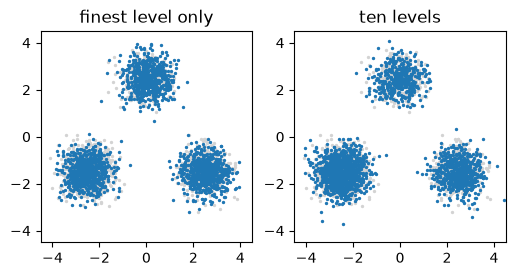

In [7]:
torch.manual_seed(0)
device = d2l.try_gpu()
mix = d2l.GaussianMixture.three_modes(device)
x_init = 3 * torch.randn(2000, 2, device=device)
x = x_init
for sig in torch.logspace(math.log10(3), math.log10(0.05), 10).tolist():
    x = d2l.langevin(lambda z: mix.score(z, 1.0, sig), x, 0.1 * sig ** 2, 100)
control = d2l.langevin(lambda z: mix.score(z, 1.0, 0.05), x_init, 0.05, 1000)
print('finest level only:', mix.summary(control))
print('ten levels:       ', mix.summary(x))
d2l.scatter_panels([control, x], ['finest level only', 'ten levels'],
                   data=mix.sample(2000));

<!-- d2l:prose id=gaussian-paths-md-7 fw=all -->

The ladder lands within about $0.03$ of the weights, with one to two percent of strays, points far from every mode, against about one percent in the data themselves. The control has the right spread around each mode but keeps the weights of its starting points, about a third each. The proportions are decided at the coarse levels, where the smoothed density has no valleys; the fine levels only sharpen each mode. A diffusion model divides the work the same way along its path. No network took part, so this experiment tests the idea alone, and whatever goes wrong later is the fault of a network.

This *annealed Langevin dynamics* sampled the first generator of this kind, the noise-conditional score network of @song2019generative. One network takes the noise level as an input and is trained by denoising score matching at every level of the ladder, weighted by $\tilde\sigma_i^2$ (that section). Its levels, step sizes and step counts were set by hand, which in high dimensions is delicate (Exercise 4). A path replaces the ten levels by a continuum, and one network must learn them all.

## Regression onto the Marginal Field

One network is to serve every point of the path. We first decide what it should learn there, then find a regression that teaches it without knowing the answer.

### Conditional Targets and Marginal Fields

The network of the previous section learned, at one noise level, the score, and with it, through Tweedie's formula, the posterior mean of the clean point, $\hat{\mathbf{x}}_0 = \mathbb{E}[\mathbf{x}_0 \mid \mathbf{x}_t]$. At every time this one object gives the score and tells a noisy point which way to move. It depends on the whole data distribution and is unknown. Condition on the clean point as well, and the problem becomes trivial: given $\mathbf{x}_0$, the best guess of $\mathbf{x}_0$ is $\mathbf{x}_0$ itself.

A sampler will need to know which way to move a noisy point, so let us ask the network for that directly. One clean point and one draw of noise move with the *conditional velocity* $\dot{\mathbf{x}}_t = \dot\alpha_t \mathbf{x}_0 + \dot\sigma_t \boldsymbol\epsilon$, which on the linear path is the constant $\boldsymbol\epsilon - \mathbf{x}_0$. Many such points pass through a given $\mathbf{x}$ at time $t$, each heading its own way, and the cloud as a whole moves there with their average velocity,

$$
\mathbf{u}_t(\mathbf{x}) = \mathbb{E}\big[\dot\alpha_t\, \mathbf{x}_0 + \dot\sigma_t\, \boldsymbol\epsilon \,\big|\, \mathbf{x}_t = \mathbf{x}\big],
$$

the *marginal velocity*. Where only one clean point can have produced $\mathbf{x}$, it is that point's velocity; where several can, it is their average, weighted by how likely each is.

For the mixture this field is exact. Given the mode, $\mathbf{x}_0$ and $\boldsymbol\epsilon$ are jointly Gaussian with $\mathbf{x}_t$, so their conditional means are linear in $\mathbf{x}_t$, and `velocity` averages them over the modes with the modes' posterior probabilities.

In [8]:
@d2l.add_to_class(d2l.GaussianMixture)
def velocity(self, x, t):
    """E[eps - x0 | x_t] on the linear path x_t = (1 - t) x0 + t eps."""
    log_p, r, var, a = self._modes(x, 1 - t, t)
    eps = (1 - a) * r / var                        # E[eps | x_t, mode k]
    x0 = self.means + a * self.std ** 2 / var * r  # E[x0 | x_t, mode k]
    return (torch.softmax(log_p, 1)[..., None] * (eps - x0)).sum(1)

<!-- d2l:prose id=gaussian-paths-md-8 fw=all -->

For real data we cannot compute this field, yet we can learn it. Least squares recovers a conditional mean, so a conditional expectation is learned by regressing on the quantity inside it. This is how denoising score matching recovered the score. For the velocity the regression gives the *conditional flow matching* loss, which differs from the regression onto the unknown marginal field only by a constant $C$ that does not depend on the network:

$$
\begin{aligned}
&\mathbb{E}_{t,\, \mathbf{x}_0,\, \boldsymbol\epsilon}\, \big\| \mathbf{u}_{\boldsymbol\theta}(\mathbf{x}_t, t) - (\dot\alpha_t \mathbf{x}_0 + \dot\sigma_t \boldsymbol\epsilon) \big\|^2 \\
&\qquad = \mathbb{E}_{t,\, \mathbf{x}_t}\, \big\| \mathbf{u}_{\boldsymbol\theta}(\mathbf{x}_t, t) - \mathbf{u}_t(\mathbf{x}_t) \big\|^2 + C.
\end{aligned}
$$

The two sides have the same minimizer, so a network trained on per-example velocities learns the marginal one (that section gives the proof). We never need $\mathbf{u}_t$ to learn it, just as the denoiser never needed the score. the figure shows both views on the mixture. With $\mathbf{x}_t = \mathbf{x}$ fixed, the conditional velocity $\boldsymbol\epsilon - \mathbf{x}_0$ of the linear path equals $(\mathbf{x} - \mathbf{x}_0)/t$, and the figure draws its negative, the direction in which a sampler moves.

![The conditional and the marginal views of the linear path on the mixture, computed exactly. (a) The conditional path of one clean point $\mathbf{x}_0$ from the heaviest mode: circles of radius $2\sigma_t$ around $\alpha_t\mathbf{x}_0$ at five times from $0$ to $1$. (b) The marginal path: contours of $p_t$ at the same times. (c) The conditional field $-(\mathbf{x} - \mathbf{x}_0)/t$ at $t = 0.5$, pointing toward that one point. (d) The marginal field $-\mathbf{u}_{0.5}(\mathbf{x})$, the posterior average of the conditional fields.](../img/mdl-diffusion-blueprint.svg)

`target` computes the per-example target on any path, and the training below asks it for the velocity. `rates` supplies $\dot\alpha_t$ and $\dot\sigma_t$ for it by forward-mode differentiation, so no path needs its derivatives written by hand. The other kinds, and `x0_eps`, which turns a prediction back into $(\hat{\mathbf{x}}_0, \hat{\boldsymbol\epsilon})$, wait for the next subsection.

In [9]:
@d2l.add_to_class(GaussianPath)
def rates(self, t):
    """The time derivatives (alpha'(t), sigma'(t)), by forward-mode AD."""
    ones = torch.ones_like(t)
    return (torch.func.jvp(self.alpha, (t,), (ones,))[1],
            torch.func.jvp(self.sigma, (t,), (ones,))[1])

@d2l.add_to_class(GaussianPath)
def target(self, kind, x0, eps, t):
    """The regression target of a kind: eps, x0, v, score or velocity."""
    t = t.reshape(-1, *[1] * (x0.dim() - 1))
    a, s = self.alpha(t), self.sigma(t)
    if kind == 'eps': return eps
    if kind == 'x0': return x0
    if kind == 'v': return a * eps - s * x0
    if kind == 'score': return -eps / s
    if kind != 'velocity': raise ValueError(f'unknown kind {kind!r}')
    da, ds = self.rates(t)                      # velocity = d x_t / dt
    return da * x0 + ds * eps

@d2l.add_to_class(GaussianPath)
def x0_eps(self, kind, out, x, t):
    """The (x0, eps) that a prediction `out` of a kind implies at (x, t)."""
    t = t.reshape(-1, *[1] * (x.dim() - 1))
    a, s = self.alpha(t), self.sigma(t)
    if kind == 'eps': return (x - s * out) / a, out
    if kind == 'x0': return out, (x - a * out) / s
    if kind == 'v': return ((a * x - s * out) / (a**2 + s**2),
                            (s * x + a * out) / (a**2 + s**2))
    if kind == 'score': return (x + s ** 2 * out) / a, -s * out
    if kind != 'velocity': raise ValueError(f'unknown kind {kind!r}')
    da, ds = self.rates(t)
    det = a * ds - s * da
    return (ds * x - s * out) / det, (a * out - da * x) / det

<!-- d2l:prose id=gaussian-paths-md-9 fw=all -->

The method now fits in one cell. Each step draws $512$ fresh points from the mixture, with a time and a noise for each, and regresses `TimeMLP`, the small network of the previous section that reads the point and sinusoidal features of the time, onto the conditional velocity of the linear path. Training runs $40{,}000$ Adam steps with a cosine-decayed learning rate and keeps a moving average of the weights, with a half-life of $700$ steps. The averaged weights smooth out the noise of the last steps, and they are the ones we evaluate below. Since every batch is new, there is no training set to memorize, unlike the fixed $2{,}000$ points of the previous section (Exercise 5 asks what happens when there is). Each network trains in a minute or two on one GPU.

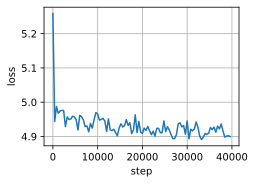

In [10]:
def regression_loss(path, kind):
    """Squared error of net(x_t, t) against the target of a kind, t ~ U(0, 1)."""
    def loss_fn(net, x0):
        t = torch.rand(len(x0), device=x0.device)
        eps = torch.randn_like(x0)
        error = net(path.sample(x0, t, eps), t) - path.target(kind, x0, eps, t)
        return (error ** 2).flatten(1).sum(1).mean()  # ||error||^2 per example
    return loss_fn

torch.manual_seed(1)
num_steps = 40_000
net_v, ema_v, losses_v = d2l.train_regression(
    d2l.TimeMLP(256, 3).to(device), regression_loss(linear, 'velocity'),
    lambda: mix.sample(512), num_steps, cosine=True, ema_half_life=700)
d2l.plot(torch.arange(100) * num_steps // 100,
         losses_v.reshape(100, -1).mean(1).cpu(), 'step', 'loss')

<!-- d2l:prose id=gaussian-paths-md-10 fw=all -->

Each point of the curve averages $400$ steps. The loss levels off near $5$ within a few thousand steps, far above zero. Is the network stuck? We will see that no network can do much better.

### Equivalent Targets

DDPM's network predicts the noise, and others predict the clean point. Does the choice change what the network learns? At a fixed $\mathbf{x}_t$ these are not different quantities. Taking the posterior mean of both sides of the equation gives $\mathbf{x}_t = \alpha_t \hat{\mathbf{x}}_0 + \sigma_t \hat{\boldsymbol\epsilon}$ with $\hat{\boldsymbol\epsilon} = \mathbb{E}[\boldsymbol\epsilon \mid \mathbf{x}_t]$, so each determines the other.

The score is a third view of the same object. Tweedie's formula of the previous section says that $\mathbb{E}[\mathbf{x}_0 \mid \tilde{\mathbf{x}}] = \tilde{\mathbf{x}} + \sigma^2 \nabla \log p_\sigma(\tilde{\mathbf{x}})$ for $\tilde{\mathbf{x}} = \mathbf{x}_0 + \sigma\boldsymbol\epsilon$. We apply it with $\alpha_t \mathbf{x}_0$ in the role of the clean point and $\sigma_t$ as the noise level. Then $\alpha_t \hat{\mathbf{x}}_0 = \mathbf{x}_t + \sigma_t^2 \nabla \log p_t(\mathbf{x}_t)$, and the score is

$$
\nabla \log p_t(\mathbf{x}_t) = \frac{\alpha_t \hat{\mathbf{x}}_0 - \mathbf{x}_t}{\sigma_t^2} = -\frac{\hat{\boldsymbol\epsilon}}{\sigma_t}.
$$

The score points from $\mathbf{x}_t$ toward the scaled posterior mean, and it is the noise prediction divided by $-\sigma_t$.

The marginal velocity the equation is $\dot\alpha_t \hat{\mathbf{x}}_0 + \dot\sigma_t \hat{\boldsymbol\epsilon}$, and eliminating $\hat{\mathbf{x}}_0$ between it and the score gives the score–velocity identity

$$
\mathbf{u}_t(\mathbf{x}) = \frac{\dot\alpha_t}{\alpha_t}\, \mathbf{x} - \Big(\sigma_t \dot\sigma_t - \sigma_t^2 \frac{\dot\alpha_t}{\alpha_t}\Big) \nabla \log p_t(\mathbf{x}).
$$

On the linear path, where $\dot\alpha_t = -1$ and $\dot\sigma_t = 1$, it reads

$$
\mathbf{u}_t(\mathbf{x}) = \hat{\boldsymbol\epsilon} - \hat{\mathbf{x}}_0 = -\frac{\mathbf{x} + t\, \nabla \log p_t(\mathbf{x})}{1 - t}.
$$

The velocity is a known multiple of the point plus a known multiple of the score, both fixed by the path. A velocity model is a score model in disguise.

Many image models use a fifth target, *$\mathbf{v}$-prediction* [@Salimans.Ho.2022], with $\mathbf{v} = \alpha_t \boldsymbol\epsilon - \sigma_t \mathbf{x}_0$. On a VP path we may write $\alpha_t = \cos\phi_t$ and $\sigma_t = \sin\phi_t$, and then $\mathbf{v} = d\mathbf{x}_t/d\phi_t$ is the velocity per unit of angle instead of per unit of time. On the cosine path without its small offset, $\phi_t = \pi t/2$, and $\mathbf{v}$ is $2/\pi$ times the velocity (Exercise 1). Salimans and Ho introduced it for samplers with very few steps, which query the network mostly at low signal-to-noise ratio. There a noise prediction yields the clean point only after division by a small $\alpha_t$, while $\mathbf{v}$ yields it without any division.

All five targets are affine functions of $\mathbf{x}_t$ and one posterior mean, with coefficients that depend only on the path and the time. We call the exact posterior mean the *oracle*, the predictor a perfect network would learn whatever its target, and the conversions between targets the *dictionary*. the table lists the dictionary in full. `target` reads it in one direction, from $(\mathbf{x}_0, \boldsymbol\epsilon)$ to a target of any kind, and `x0_eps`, defined beside it above, reads it back, from a prediction of any kind to $(\hat{\mathbf{x}}_0, \hat{\boldsymbol\epsilon})$. A network trained on one target therefore defines all of them, and so does a network trained on another path, read at the time of equal log-SNR.

Let us watch the dictionary at one point. For the mixture, `oracle` returns the exact $\hat{\mathbf{x}}_0$ and $\hat{\boldsymbol\epsilon}$, so any loss or sampler can use it in place of a network. At the point $(0.5, -0.5)$ of the VP path at $t = 0.5$, where $\alpha = 0.28$ and $\sigma = 0.96$, we print every target. The last line rescales the point by $1/(\alpha + \sigma)$ onto the linear path at equal log-SNR, $t = 0.773$, and evaluates the exact field `velocity` there, a different formula at a different point. It should return $\hat{\boldsymbol\epsilon} - \hat{\mathbf{x}}_0$, which the first two lines let us compute in advance.

In [11]:
def oracle(x, alpha, sigma):
    """The exact posterior means (x0_hat, eps_hat) of the mixture at x."""
    x0_hat = mix.posterior_mean(x, alpha, sigma)
    a, s = (torch.as_tensor(v, device=x.device).reshape(-1, 1)
            for v in (alpha, sigma))
    return x0_hat, (x - a * x0_hat) / s

x = torch.tensor([[0.5, -0.5]], device=device)   # one noisy point
t = torch.tensor([0.5], device=device)           # VP: alpha 0.28, sigma 0.96
x0_hat, eps_hat = oracle(x, vp.alpha(t), vp.sigma(t))
for kind in ('x0', 'eps', 'score', 'v', 'velocity'):
    print(f'{kind:>8} on vp:', r2(vp.target(kind, x0_hat, eps_hat, t)[0]))
c = 1 / (vp.alpha(t) + vp.sigma(t))     # linear path, same alpha / sigma
print(f'velocity on linear at t = {(c * vp.sigma(t)).item():.3f}:',
      r2(mix.velocity(c * x, c * vp.sigma(t))[0]),
      ' eps_hat - x0_hat:', r2((eps_hat - x0_hat)[0]))

      x0 on vp: [0.29, -0.98]
     eps on vp: [0.44, -0.23]
   score on vp: [-0.46, 0.24]
       v on vp: [-0.15, 0.88]
velocity on vp: [-0.22, 1.29]
velocity on linear at t = 0.773: [0.15, 0.75]  eps_hat - x0_hat: [0.15, 0.75]


<!-- d2l:prose id=gaussian-paths-md-11 fw=all -->

The clean point is predicted at $(0.29, -0.98)$, inside the triangle of the three means $(-2.5, -1.5)$, $(2.5, -1.5)$ and $(0, 2.5)$ and near none of them, because at $\alpha = 0.28$ the posterior still spreads over all three modes. The score is the noise prediction divided by $-0.96$, and the field of the linear path returns $(0.15, 0.75) = \hat{\boldsymbol\epsilon} - \hat{\mathbf{x}}_0$. Five targets on two paths come from one posterior mean.

Which target should we train, then? A network that reached the oracle would not care. A real network does not reach it, and two practical facts decide. First, a noise predictor says nothing about the clean point at pure noise, where $\hat{\mathbf{x}}_0 = (\mathbf{x}_t - \sigma_t \hat{\boldsymbol\epsilon})/\alpha_t$ divides by zero, so it belongs on a path whose $\alpha_t$ stays positive, such as VP. Second, the targets weigh the times differently. On the linear path the velocity loss is the noise loss weighted by $1/(1 - t)^2$ and the clean-point loss weighted by $1/t^2$ (Exercise 2), so equal squared errors in the velocity mean small errors of the noise near the noise end and small errors of the clean point near the data. In practice three pairs dominate: the velocity on the linear path, $\mathbf{v}$ on a cosine path and the noise on a VP path. None of the three is wrong, and the dictionary converts between them.

DDPM's *simple loss* [@ho2020denoising] regresses onto the noise,

$$
\begin{aligned}
L_{\textrm{simple}}(\boldsymbol\theta)
&= \mathbb{E}_{t,\, \mathbf{x}_0,\, \boldsymbol\epsilon}\, \big\| \boldsymbol\epsilon - \boldsymbol\epsilon_{\boldsymbol\theta}(\alpha_t \mathbf{x}_0 + \sigma_t \boldsymbol\epsilon,\, t) \big\|^2 .
\end{aligned}
$$

The per-example score, that of the conditional density $\mathcal{N}(\alpha_t \mathbf{x}_0, \sigma_t^2 \mathbf{I})$ of $\mathbf{x}_t$ given $\mathbf{x}_0$, is $-\boldsymbol\epsilon/\sigma_t$, so the simple loss is denoising score matching at every level, weighted by $\sigma_t^2$ (that section). Ho et al. derived it from a variational bound on the likelihood and then dropped the bound's weights over $t$, because the samples looked better without them. Our second model makes DDPM's choice, the noise target on the VP path, and changes nothing else.

In [12]:
torch.manual_seed(2)
net_eps, ema_eps, losses_eps = d2l.train_regression(
    d2l.TimeMLP(256, 3).to(device), regression_loss(vp, 'eps'),
    lambda: mix.sample(512), num_steps, cosine=True, ema_half_life=700)

<!-- d2l:prose id=gaussian-paths-md-12 fw=all -->

If both networks trained well, the dictionary says that they hold the same posterior mean despite their different paths and targets. The loss floor lets us check.

### The Loss Floor

Why did the velocity loss level off near $5$? A target contains the noise of its own example, which no network can predict from $\mathbf{x}_t$. Even the oracle keeps the conditional variance of the target, averaged over the path. This *loss floor*, which the previous section met at one noise level, is the constant $C$ of the equation. Once $\mathbf{x}_t$ is fixed, the noise is $(\mathbf{x}_t - \alpha_t \mathbf{x}_0)/\sigma_t$, so every target is $c_t \mathbf{x}_0$ plus a function of $\mathbf{x}_t$, and its floor at time $t$ is

$$
c_t^2\; \mathbb{E}\, \textrm{tr}\, \textrm{Cov}[\mathbf{x}_0 \mid \mathbf{x}_t].
$$

The clean point has $c_t = 1$, the noise $c_t = -\alpha_t/\sigma_t$, the velocity of the linear path $c_t = -1/t$. The targets differ only in how much they magnify one posterior variance.

Near the data we can predict the number. At $t = 0.1$ the modes are still far apart compared with the noise, so the posterior is that of a single Gaussian mode, with variance $s^2 \sigma_t^2 / (\alpha_t^2 s^2 + \sigma_t^2)$ per coordinate. Multiplied by $c_t^2$ and summed over the two coordinates, it gives the noise floor $2\alpha_t^2 s^2/(\alpha_t^2 s^2 + \sigma_t^2)$ and the velocity floor $2 s^2/(\alpha_t^2 s^2 + \sigma_t^2)$ of the linear path, where $\sigma_t = t$. With $s = 0.5$, the VP path ($\alpha = 0.95$, $\sigma = 0.32$) has a noise floor of about $1.37$, and the linear path ($\alpha = 0.9$, $\sigma = 0.1$) a velocity floor of $2.35$.

The cell measures each floor on a million draws, at three times and averaged over $t$, with its standard error. Any network's loss splits into the floor plus the mean squared distance between its prediction and the oracle's, because the oracle's error is uncorrelated with every function of $\mathbf{x}_t$. The cell therefore measures the excess of the averaged network over the floor directly, as that distance (column `excess`), and prints the training loss of the last $1{,}000$ steps beside it (column `train loss`). The last line reads the velocity network as a noise predictor on the VP path: `eps_from_velocity` moves each point to the linear path at equal log-SNR, asks the velocity network there, and converts its answer to $\hat{\boldsymbol\epsilon}$ with `x0_eps`.

In [13]:
@torch.no_grad()
def floor_and_excess(path, kind, net, x0, eps, t):
    """The floor E||target - E[target | x_t]||^2 with its standard error, and
    the network's loss minus the floor, E||net(x_t, t) - E[target | x_t]||^2."""
    x = path.sample(x0, t, eps)
    best = path.target(kind, *oracle(x, path.alpha(t), path.sigma(t)), t)
    err = ((path.target(kind, x0, eps, t) - best) ** 2).sum(1)
    out = torch.cat([net(x[i:i + 100_000], t[i:i + 100_000])  # in chunks
                     for i in range(0, len(x), 100_000)])
    return (err.mean().item(), err.std().item() / math.sqrt(len(err)),
            ((out - best) ** 2).sum(1).mean().item())

def eps_from_velocity(x, t):
    """ema_v as a noise predictor on the VP path, read at the linear-path
    time with the same alpha / sigma (the same posterior mean)."""
    c = 1 / (vp.alpha(t) + vp.sigma(t))
    t_lin, x_lin = c * vp.sigma(t), c[:, None] * x
    return linear.x0_eps('velocity', ema_v(x_lin, t_lin), x_lin, t_lin)[1]

n = 1_000_000
x0, eps = mix.sample(n), torch.randn(n, 2, device=device)
times = [torch.full((n,), t, device=device) for t in (0.1, 0.5, 0.9)]
times.append(torch.rand(n, device=device))             # t ~ U(0, 1)
print('target, path      t=0.1  t=0.5  t=0.9  t~U(0,1)    s.e.'
      '  train loss   excess')
for name, path, kind, net, losses in (
        ('noise, vp', vp, 'eps', ema_eps, losses_eps),
        ('velocity, linear', linear, 'velocity', ema_v, losses_v)):
    rows = [floor_and_excess(path, kind, net, x0, eps, t) for t in times]
    print(f'{name:16}' + ''.join(f'{r[0]:7.3f}' for r in rows[:3])
          + f'{rows[3][0]:10.3f}{rows[3][1]:8.4f}'
          + f'{losses[-1000:].mean().item():12.3f}{rows[3][2]:9.4f}')
floor, _, gap = floor_and_excess(vp, 'eps', eps_from_velocity, x0, eps,
                                 times[3])
print(f'velocity net read as a noise model on vp: loss {floor + gap:.3f},'
      f' excess {gap:.4f}')

target, path      t=0.1  t=0.5  t=0.9  t~U(0,1)    s.e.  train loss   excess


noise, vp         1.368  0.477  0.002     0.540  0.0011       0.542   0.0002


velocity, linear  2.351  2.796  9.157     4.906  0.0070       4.899   0.0010
velocity net read as a noise model on vp: loss 0.540, excess 0.0002


<!-- d2l:prose id=gaussian-paths-md-13 fw=all -->

The floors at $t = 0.1$ match our single-mode analytical estimate within $0.01$. Along the path the two floors move in opposite directions: the noise floor is largest near $t = 0$ (where small noise is indistinguishable from within-mode variance) and falls to $0.002$ at $t = 0.9$, whereas the velocity floor rises to $\approx 9$ at $t = 0.9$ before settling to $\operatorname{tr}\textrm{Cov}[\mathbf{x}_0]$ at $t = 1$ (Exercise 3). Averaged over $t \sim U(0, 1)$, the floors differ by an order of magnitude ($0.54$ for noise vs. $4.9$ for velocity) because of the target scaling $c_t^2$ and the different clocks of the two paths.

Both trained networks reach their theoretical floors: the mean squared error against the exact oracle (`excess`) is $0.0002$ for the noise network and $0.001$ for the velocity network, well below the Monte Carlo standard error of the floor itself. Moreover, when the linear-path velocity network is queried as a VP noise predictor via `eps_from_velocity`, it achieves the exact same loss ($0.540$) and excess ($0.0002$) as the network trained directly on the VP noise target. Both networks have learned the same underlying posterior mean. (A raw score target $-\boldsymbol\epsilon/\sigma_t$ divides the noise floor by $\sigma_t^2$ and diverges as $t \to 0$, which is why score networks weight the DSM objective by $\sigma_t^2$, reducing it to noise prediction.) Turning these learned fields into samples is the subject of that section.

## Summary

A Gaussian path $\mathbf{x}_t = \alpha_t \mathbf{x}_0 + \sigma_t \boldsymbol\epsilon$ interpolates between clean data at $t = 0$ and Gaussian noise at $t = 1$, and all such paths share a canonical clock given by the log signal-to-noise ratio $\lambda_t = \log(\alpha_t^2 / \sigma_t^2)$. Annealing across noise levels resolves the single-level dilemma because high-noise levels establish global mode weights across smoothed valleys while low-noise levels sharpen each mode. Regressing onto per-example conditional targets ($\mathbf{x}_0$, $\boldsymbol\epsilon$, $-\boldsymbol\epsilon/\sigma_t$, $\mathbf{v}$, or $\dot\alpha_t \mathbf{x}_0 + \dot\sigma_t \boldsymbol\epsilon$) trains a network to output the corresponding conditional expectation given $\mathbf{x}_t$; since all five targets are affine functions of $\mathbf{x}_t$ and $\hat{\mathbf{x}}_0 = \mathbb{E}[\mathbf{x}_0 \mid \mathbf{x}_t]$, a single trained predictor determines all five across any Gaussian path. Finally, every per-example regression objective has a positive loss floor $c_t^2\, \mathbb{E}\operatorname{tr}\textrm{Cov}[\mathbf{x}_0 \mid \mathbf{x}_t]$ arising from the unobserved noise realization, so predictor accuracy is measured by the excess loss above this floor rather than by the raw training loss.

## Exercises

1. **From $\mathbf{v}$ to the velocity.** At the point $\mathbf{x} = (0.5, -0.5)$ of the VP path at $t = 0.5$, where $\alpha_t = 0.28$ and $\sigma_t = 0.96$, the text printed the exact prediction $\hat{\mathbf{v}} = (-0.15, 0.88)$.
    1. On a VP path $\alpha_t^2 + \sigma_t^2 = 1$. Show that $\hat{\mathbf{x}}_0 = \alpha_t \mathbf{x} - \sigma_t \hat{\mathbf{v}}$ and $\hat{\boldsymbol\epsilon} = \sigma_t \mathbf{x} + \alpha_t \hat{\mathbf{v}}$, and recover the printed $\hat{\mathbf{x}}_0$ and $\hat{\boldsymbol\epsilon}$ by hand. Rounding the inputs to two digits costs about $0.01$.
    1. Write $\alpha_t = \cos\phi_t$ and $\sigma_t = \sin\phi_t$. Show that the velocity is $\mathbf{u}_t = \dot\phi_t\, \mathbf{v}$, so that $\mathbf{v}$ is the velocity per unit of angle, and deduce the factor $2/\pi$ of the cosine path.
    1. For the VP path of this section show that $\dot\phi_t = \beta(t)\, \alpha_t / (2 \sigma_t)$. Evaluate it at $t = 0.5$ and recover the printed velocity $(-0.22, 1.29)$ from $\hat{\mathbf{v}}$, to within the rounding of the first part.
1. **Velocity, noise and clean-point targets.** On the linear path, take the posterior mean of $\mathbf{x}_t = (1 - t)\mathbf{x}_0 + t\boldsymbol\epsilon$.
    1. Show that the marginal velocity equals both $(\mathbf{x} - \hat{\mathbf{x}}_0)/t$ and $(\hat{\boldsymbol\epsilon} - \mathbf{x})/(1 - t)$.
    1. By the first part, an error in $\hat{\mathbf{x}}_0$ reaches the velocity divided by $t$, and an error in $\hat{\boldsymbol\epsilon}$ divided by $1 - t$. Near which end of the path is each prediction a poor source of the velocity, and how does this explain why a noise model is never queried at $\alpha = 0$? (Exercise 6 of that section works out the propagation of errors between all targets on the cosine path.)
    1. Show that the velocity loss of $\mathbf{u}_{\boldsymbol\theta} = (\mathbf{x} - \hat{\mathbf{x}}_{0,\boldsymbol\theta})/t$ equals the clean-point loss $\mathbb{E}\|\hat{\mathbf{x}}_{0,\boldsymbol\theta} - \mathbf{x}_0\|^2$ weighted by $1/t^2$, and the velocity loss of $\mathbf{u}_{\boldsymbol\theta} = (\hat{\boldsymbol\epsilon}_{\boldsymbol\theta} - \mathbf{x})/(1 - t)$ equals the noise loss weighted by $1/(1 - t)^2$. Which times does flow matching emphasize relative to each of the two unweighted losses?
1. [code] **The loss floor.** Use `oracle` and `floor_and_excess`.
    1. Plot the floor of the velocity target on the linear path and of the noise target on the VP path against $t$ on a grid in $(0, 1)$. Where is each largest? The printed training loss is a mean over $1{,}000$ minibatches of $512$ points; estimate its standard error from `losses_v`, and compare it with the gap between the printed training loss and the floor.
    1. Let $\boldsymbol\Sigma$ be the covariance matrix of the mixture, with eigenvalues $\kappa_1, \kappa_2$. For Gaussian data with this covariance, show that the velocity floor on the linear path at time $t$ is $\sum_i \kappa_i / \big((1 - t)^2 \kappa_i + t^2\big)$. Add this curve to the plot, and explain why it cannot lie below the floor of the mixture. Why do the two floors agree at both ends of the path?
    1. The score target $-\boldsymbol\epsilon/\sigma_t$ has the floor of the noise target divided by $\sigma_t^2$. Evaluate it on the VP path at $t = 0.01$, $0.1$ and $0.5$, and explain why no network is trained on this target with $t$ uniform on $(0, 1)$.
    1. The noise model's training loss is about a tenth of the velocity model's. Is it the better model? At the VP times $t \in \{0.1, 0.5, 0.9\}$ measure each network's error against the oracle in a common unit, $\mathbb{E}\|\hat{\mathbf{x}}_0 - \hat{\mathbf{x}}_0^\star\|^2$, where $\hat{\mathbf{x}}_0^\star$ comes from `oracle`. Convert `ema_eps` with `vp.x0_eps`, and `ema_v` with `eps_from_velocity` followed by $\hat{\mathbf{x}}_0 = (\mathbf{x}_t - \sigma_t \hat{\boldsymbol\epsilon})/\alpha_t$. Use the factors $c_t$ of the text to explain why the raw losses differ so much. Which comparison ranks the two models: the raw losses, their excesses over the floors, or the errors in a common unit?

    *Part (d) is adapted from CMU 10-799, [Homework 2](https://kellyyutonghe.github.io/10799S26/assets/pdf/hw2.pdf) (Spring 2026), Question 3(a).*
1. **Ladder spacing in high dimensions.** ● Let the data be a single point at the origin of $\mathbb{R}^d$, so that $p_{\tilde\sigma} = \mathcal{N}(\mathbf{0}, \tilde\sigma^2 \mathbf{I})$, and let the ladder be geometric with ratio $q = \tilde\sigma_{i-1}/\tilde\sigma_i > 1$.
    1. Show that $r = \|\mathbf{x}\|$ for $\mathbf{x} \sim p_{\tilde\sigma}$ satisfies $\mathbb{E}[r^2] = d\tilde\sigma^2$ and $\textrm{Var}[r^2] = 2d\tilde\sigma^4$, and conclude that $r$ is approximately $\mathcal{N}(\tilde\sigma\sqrt d, \tilde\sigma^2/2)$ for large $d$.
    1. A chain that leaves level $i - 1$ with a sample of $p_{\tilde\sigma_{i-1}}$ enters level $i$ at a radius that lies, with high probability, in $\tilde\sigma_{i-1}(\sqrt d \pm 3/\sqrt 2)$. Show that $p_{\tilde\sigma_i}$ puts the mass $\Phi\big(\sqrt{2d}(q - 1) + 3q\big) - \Phi\big(\sqrt{2d}(q - 1) - 3q\big)$ on this interval, where $\Phi$ is the standard normal distribution function. Why does a mass near zero mean that the chain starts the level where the network has seen almost no training inputs?
    1. @Song.Ermon.2020 choose $q$ so that this mass is about one half. Solve for $q$ at $d = 3072$, the dimension of CIFAR-10 images, and count the levels from $\tilde\sigma = 50$ down to $0.01$. Compare with the $232$ levels of their CIFAR-10 model.
    1. The top level must also be coarse enough to merge the modes. Two equal Gaussian components at $\pm\mu$ with variance $v$ have a single mode exactly when $\mu^2 \le v$ (Exercise 4 of that section). Use this criterion on the two lower modes of the mixture to estimate the noise level at which they merge, and compare it with the ladder's top level of $3$.

<!-- d2l:prose id=gaussian-paths-md-14 fw=pytorch -->

5. [code] **The exact optimum memorizes.** A finite training set is itself a distribution, a mixture of point masses, and its exact velocity field is known. @Bertrand.Gagneux.Massias.ea.2025 take as their starting point that following this field from noise reproduces the training points, and ask why trained networks generalize instead.
    1. Draw $64$ points from the mixture and train `TimeMLP(256, 3)` with `regression_loss(linear, 'velocity')` on batches drawn from these points only.
    1. `d2l.GaussianMixture(points.tolist(), [1/64] * 64, 0.0)` is the empirical distribution (also pass the `device`), and its `velocity` method is the exact field for $t > 0$. Follow it and the trained network from the same $2{,}000$ standard Gaussian starts, with $100$ straight steps $\mathbf{x} \leftarrow \mathbf{x} - \mathbf{u}_t(\mathbf{x})/100$ at $t = 1, 0.99, \ldots, 0.01$. For both sets of samples, plot the histogram of the distance to the nearest training point.
    1. Which field reproduces the training set, and which produces new points? Bertrand et al. argue that the noise in the regression targets is not what makes the network generalize. Repeat the first two parts with $1{,}024$ training points, and describe how the two histograms change.

<!-- d2l:prose id=gaussian-paths-md-15 fw=all -->

[Discussions](https://d2l.discourse.group/t/36888)